# 02 — Разведочный анализ: Bank Marketing (bank-additional-full)

**Датасет:** [Bank Marketing (Kaggle)](https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing) —
41 188 клиентов банка Португалии, 20 признаков, целевая переменная `y`
(подписался ли клиент на срочный депозит по итогам телефонной кампании).

**Задачи ноутбука (роль Data Scientist):**
1. структура данных, баланс классов;
2. анализ «unknown»-категорий и качества данных;
3. **обнаружение утечки целевой переменной** (признак `duration`);
4. анализ признаков кампании (`pdays`, `previous`, `poutcome`);
5. сезонность и макроэкономические признаки;
6. выводы и стратегия предобработки.

In [1]:
# --- Setup ---------------------------------------------------------------
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DATASETS
from src.datasets import load_raw_by_key
from src.plotting import setup_style

setup_style()
pd.set_option("display.max_columns", 40)

spec = DATASETS["bank"]
print(f"Источник (Kaggle): {spec.kaggle_url}")
print(f"Задача: {spec.task_summary}")
print("Примечания:", *spec.notes, sep="\n  - ")

Источник (Kaggle): https://www.kaggle.com/datasets/henriqueyamahata/bank-marketing
Задача: Прогноз подписки клиента банка на срочный депозит по итогам маркетинговой кампании (y = yes/no).
Примечания:
  - Явная утечка целевой переменной: признак duration (длительность звонка) известен только после контакта.
  - Дисбаланс классов ~89% / 11%.
  - Категория 'unknown' в нескольких признаках.


## 1. Знакомство с данными

In [2]:
raw = load_raw_by_key("bank")
print(f"Размер таблицы: {raw.shape[0]} строк × {raw.shape[1]} признаков")
raw.head()

Размер таблицы: 41188 строк × 21 признаков


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


**Структура:** 10 категориальных признаков (job, marital, education, default, housing,
loan, contact, month, day_of_week, poutcome) и 10 числовых (age, duration, campaign,
pdays, previous + 5 макроэкономических показателей).

## 2. Баланс классов

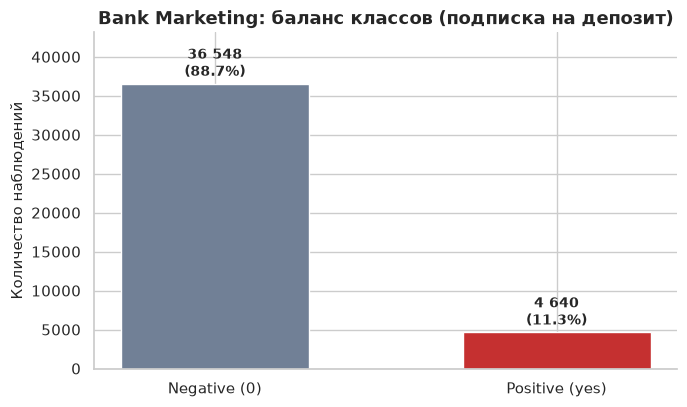

In [5]:
from src.plotting import plot_target_balance

y = (raw["y"] == "yes").astype(int)
fig = plot_target_balance(y, "Bank Marketing: баланс классов (подписка на депозит)", positive_label="yes")
plt.show()

**Дисбаланс сильнее, чем в Telco:** только 11.3% клиентов подписываются.
Accuracy бесполезен как одиночная метрика; ключевые — **ROC-AUC, F1, Recall**
(банку важно не пропустить потенциального вкладчика).

## 3. Качество данных: категории 'unknown'

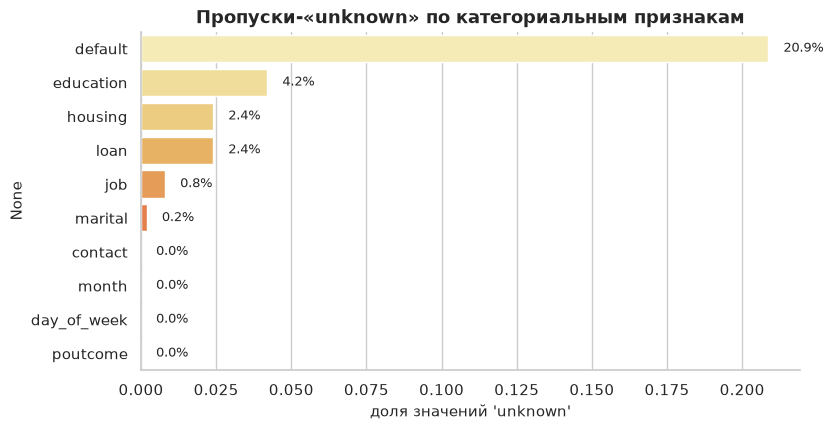

In [6]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
unknown_share = pd.Series(
    {c: (raw[c] == "unknown").mean() for c in cat_cols}
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.4))
sns.barplot(x=unknown_share.values, y=unknown_share.index, hue=unknown_share.index,
            palette="YlOrRd", legend=False, ax=ax)
for i, v in enumerate(unknown_share.values):
    ax.text(v + 0.005, i, f"{v:.1%}", va="center", fontsize=9)
ax.set_xlabel("доля значений 'unknown'")
ax.set_title("Пропуски-«unknown» по категориальным признакам")
plt.show()

**Наблюдения:**
- `default` (был ли дефолт) почти целиком 'unknown'/'no' — признак почти неинформативен;
- `job`, `education`, `housing`, `loan` содержат 0.8–25% 'unknown';

**Стратегия:** 'unknown' оставляем как **отдельный уровень** категории
(он сам по себе может быть сигналом — клиент не захотел отвечать),
а не выбрасываем строки (потеряли бы до 25% данных).

## 4. Утечка целевой переменной: признак `duration`

`duration` — длительность последнего звонка. Она известна **только после
завершения контакта**, поэтому для предсказания «подпишется ли клиент»
до/во время звонка этот признак использовать нельзя — это классическая
**утечка данных (data leakage)**. Посмотрим, насколько он силен:

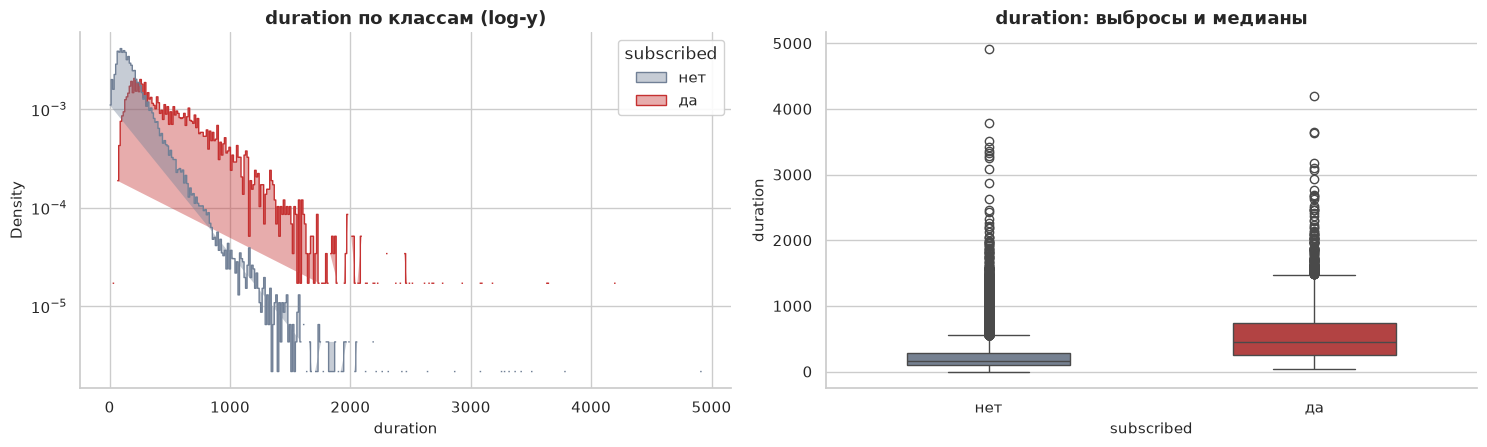

Медиана duration при y=no : 163.5 сек
Медиана duration при y=yes: 449.0 сек


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

plot_df = raw.assign(subscribed=raw["y"].map({"no": "нет", "yes": "да"}))
sns.histplot(data=plot_df, x="duration", hue="subscribed", stat="density",
             element="step", common_norm=False, palette=["#718096", "#c53030"],
             log_scale=(False, True), ax=axes[0], alpha=0.4)
axes[0].set_title("duration по классам (log-y)")

sns.boxplot(data=plot_df, x="subscribed", y="duration", hue="subscribed",
            palette=["#718096", "#c53030"], legend=False, ax=axes[1], width=0.5)
axes[1].set_title("duration: выбросы и медианы")
fig.tight_layout()
plt.show()

print("Медиана duration при y=no :", raw.loc[raw.y == "no", "duration"].median(), "сек")
print("Медиана duration при y=yes:", raw.loc[raw.y == "yes", "duration"].median(), "сек")

In [8]:
# Корреляция duration с таргетом
corr = np.corrcoef(raw["duration"], y)[0, 1]
print(f"Корреляция duration ↔ подписка: {corr:.3f}")

Корреляция duration ↔ подписка: 0.405


**Вывод:** распределения почти разделимы — средний звонок подписавшегося клиента
в 3–4 раза дольше. Модель с `duration` «обучится» простому правилу
«длинный звонок → да», что на практике бесполезно (звонок ещё идёт!).

**Решение:** `duration` **исключается** из матрицы признаков (`src/features.py`,
`src/preprocessing.prepare_matrix`), а эффект утечки измеряется отдельным
экспериментом (ноутбук 03 / `reports/metrics/bank_duration_leakage.csv`).

## 5. Признаки кампании: `pdays`, `previous`, `poutcome`

pdays == 999 (не контактировали раньше): 0.9632174419733903
previous == 0: 0.8634310964358551


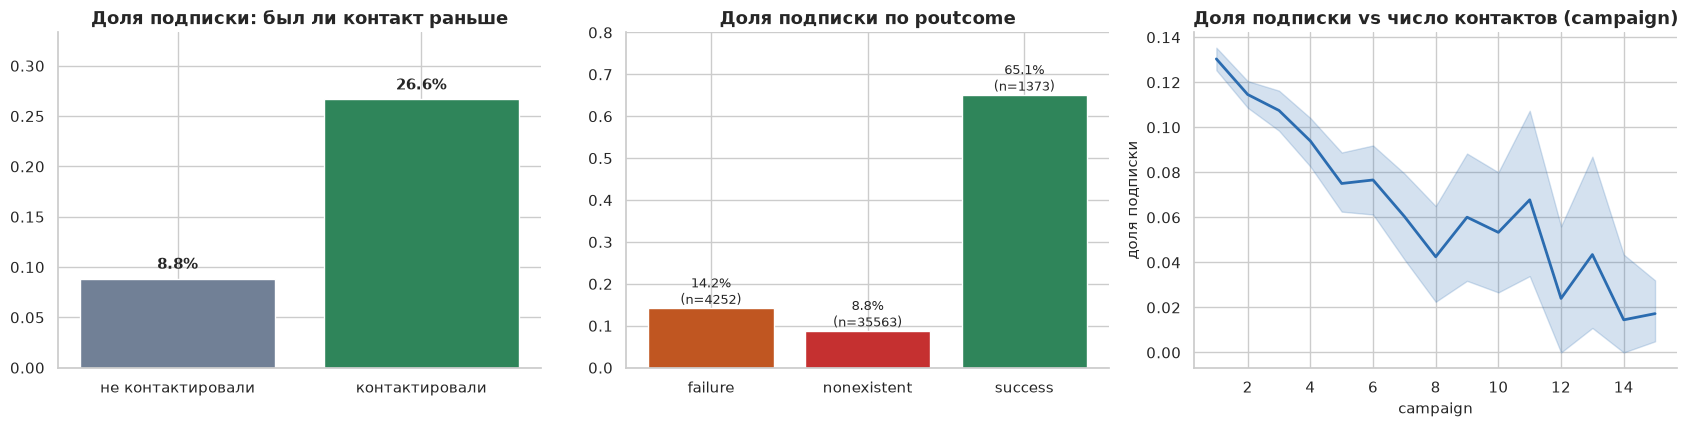

In [9]:
print("pdays == 999 (не контактировали раньше):", (raw["pdays"] == 999).mean())
print("previous == 0:", (raw["previous"] == 0).mean())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

# 1) Уже были контакты?
tmp = raw.assign(was_contacted=raw["previous"] > 0, subscribed=y)
rate = tmp.groupby("was_contacted")["subscribed"].mean()
axes[0].bar(["не контактировали", "контактировали"], rate.values,
            color=["#718096", "#2f855a"])
for i, v in enumerate(rate.values):
    axes[0].text(i, v + 0.01, f"{v:.1%}", ha="center", fontweight="bold")
axes[0].set_title("Доля подписки: был ли контакт раньше")
axes[0].set_ylim(0, rate.max() * 1.25)

# 2) Результат прошлой кампании
part = raw.assign(subscribed=y).groupby("poutcome")["subscribed"].agg(["mean", "count"])
axes[1].bar(part.index, part["mean"], color=["#c05621", "#c53030", "#2f855a"])
for i, (v, n) in enumerate(zip(part["mean"], part["count"])):
    axes[1].text(i, v + 0.01, f"{v:.1%}\n(n={n})", ha="center", fontsize=9)
axes[1].set_title("Доля подписки по poutcome")
axes[1].set_ylim(0, 0.8)

# 3) Количество контактов в текущей кампании
sns.lineplot(data=raw.assign(subscribed=y, campaign=raw["campaign"].clip(upper=15)),
             x="campaign", y="subscribed", errorbar=("ci", 95), ax=axes[2],
             color="#2b6cb0", lw=2)
axes[2].set_title("Доля подписки vs число контактов (campaign)")
axes[2].set_ylabel("доля подписки")
fig.tight_layout()
plt.show()

**Находки:**
- клиенты, с которыми **уже контактировали** (`previous > 0`), подписываются вдвое чаще;
- `poutcome = success` — мощнейший сигнал (≈ 65% подписки против 9% у остальных);
- рост числа контактов `campaign` после 4–6 звонков **снижает** конверсию —
  настойчивость утомляет клиентов → инженерия: `campaign_log`, `was_contacted_before`.

## 6. Сезонность и макроэкономика

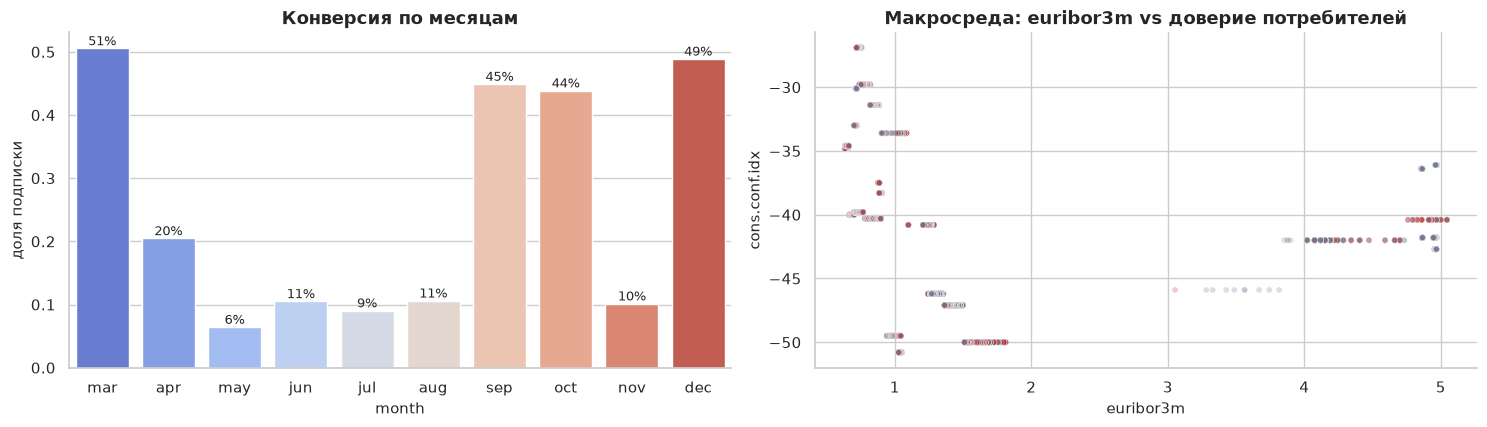

In [10]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_rate = raw.assign(subscribed=y).groupby("month")["subscribed"].agg(["mean", "count"])
month_rate = month_rate.reindex(month_order).dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
sns.barplot(x=month_rate.index, y=month_rate["mean"], hue=month_rate.index,
            palette="coolwarm", legend=False, ax=axes[0])
for i, (v, n) in enumerate(zip(month_rate["mean"], month_rate["count"])):
    axes[0].text(i, v + 0.005, f"{v:.0%}", ha="center", fontsize=9)
axes[0].set_title("Конверсия по месяцам")
axes[0].set_ylabel("доля подписки")

econ = raw.assign(subscribed=y)
sns.scatterplot(data=econ, x="euribor3m", y="cons.conf.idx", hue="subscribed",
                palette={0: "#718096", 1: "#c53030"}, alpha=0.25, s=18,
                ax=axes[1], legend=False)
axes[1].set_title("Макросреда: euribor3m vs доверие потребителей")
fig.tight_layout()
plt.show()

**Наблюдения:**
- пики конверсии — **март, сентябрь, октябрь** (начало учебного года, «майский» провал —
  массовые кампании приносят усталость);
- `euribor3m` (ставка межбанковского рынка) хорошо разделяет периоды кампании —
  макропризнаки почти однозначно кодируют дату контакта;
- для модели оставляем и сезон (`season` из месяца), и макропризнаки.

## 7. Числовые признаки и выбросы

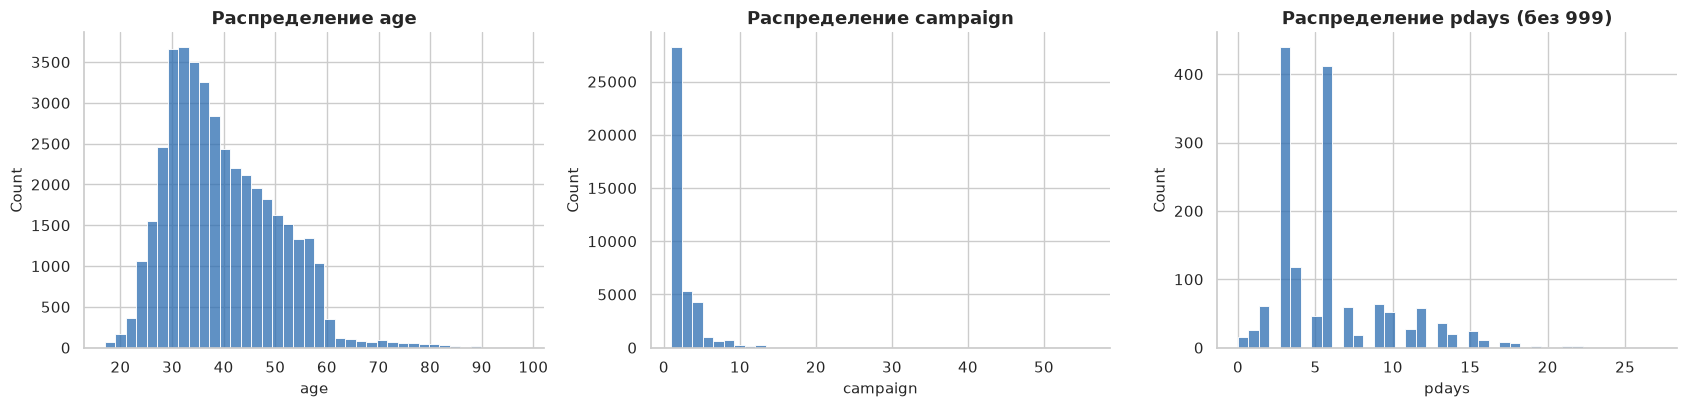

age: выбросов 1.5*IQR — 469 (1.14%)
campaign: выбросов 1.5*IQR — 2406 (5.84%)


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col in zip(axes, ["age", "campaign", "pdays"]):
    data = raw[col].replace(999, np.nan) if col == "pdays" else raw[col]
    sns.histplot(data.dropna(), bins=40, ax=ax, color="#2b6cb0")
    ax.set_title(f"Распределение {col}" + (" (без 999)" if col == "pdays" else ""))
fig.tight_layout()
plt.show()

for col in ["age", "campaign"]:
    s = raw[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    print(f"{col}: выбросов 1.5*IQR — {out} ({out/len(s):.2%})")

**Вывод:** `campaign` имеет длинный хвост (до 56 контактов) — логарифмируем
(`campaign_log`); возрастные «выбросы» (70–90 лет) — реальные клиенты, оставляем.

## 8. Корреляционный анализ

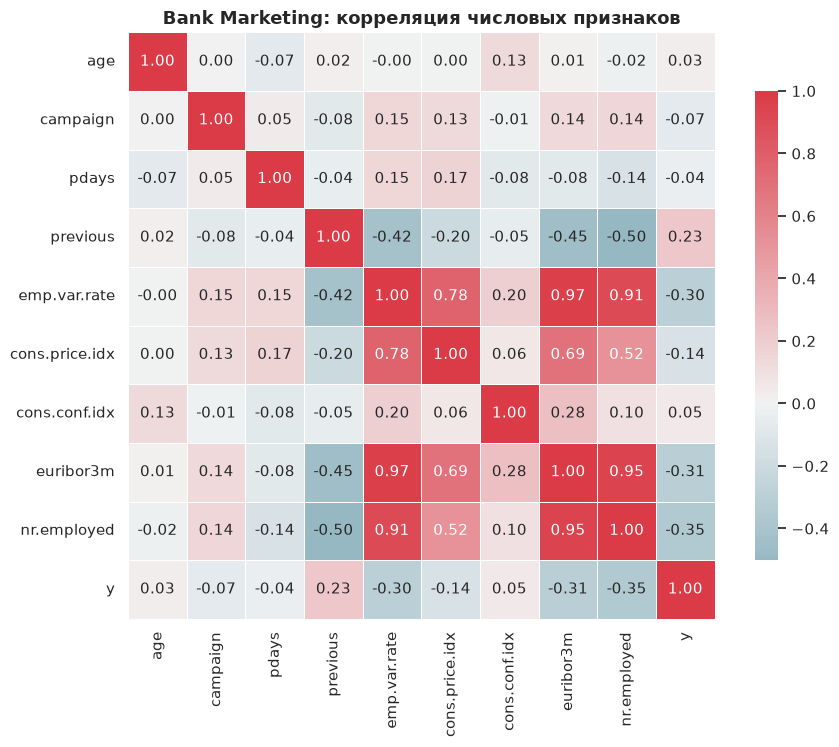

In [12]:
from src.plotting import plot_correlation_heatmap

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
corr_df = raw[num_cols].replace(999, np.nan).copy()
corr_df["subscribed"] = y
fig = plot_correlation_heatmap(corr_df.rename(columns={"subscribed": "y"}),
                               "Bank Marketing: корреляция числовых признаков", annot=True)
plt.show()

**Мультиколлинеарность:** `emp.var.rate`, `euribor3m`, `nr.employed` сильно
коррелируют между собой (все описывают макросреду). Для линейной модели это
лечится регуляризацией, для бустинга — не проблема (деревья выбирают один из
коррелированных признаков).

## 9. Выводы по EDA (Bank Marketing)

| # | Находка | Решение в пайплайне |
|---|---------|---------------------|
| 1 | **Утечка:** `duration` сильно коррелирует с таргетом, но неизвестен к моменту предсказания | исключён из матрицы признаков; эффект измерен экспериментом |
| 2 | Дисбаланс 89/11 | stratified split, `class_weight='balanced'`, метрики F1/ROC-AUC/PR-AUC |
| 3 | `pdays = 999` — сентинел «не контактировали» | замена на `NaN` + признак `was_contacted_before`, `pdays_recency` |
| 4 | `poutcome=success` и прошлые контакты — сильный сигнал | признаки `was_contacted_before`, `pdays_recency` |
| 5 | 'unknown'-категории до 25% | сохраняются как отдельный уровень (не теряем данные) |
| 6 | Длинный хвост `campaign` | `campaign_log = log1p(campaign)` |
| 7 | Сезонность и макропризнаки | `season` из месяца + исходные макропризнаки |

Датасет готов к моделированию → ноутбук **03**.